In [1]:

# Matplotlib Session 7 - Task 1
# Generate Gym Members Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set random seed
np.random.seed(42)

# Generate 400 gym members
n = 400

# Create gym dataset
df = pd.DataFrame({
    "age": np.random.randint(18, 61, size=n),

    "plan": np.random.choice(
        ["Basic", "Standard", "Premium"],
        size=n
    ),

    "join_month": np.random.randint(1, 13, size=n),

    "months_active": np.random.randint(1, 37, size=n)
})

# Visits grow slightly with plan level
plan_bonus = df["plan"].map({
    "Basic": 0,
    "Standard": 3,
    "Premium": 6
})

df["visits_per_month"] = np.clip(
    np.random.normal(9, 4, size=n) + plan_bonus,
    0,
    25
).round().astype(int)

# Save dataset
df.to_csv("gym_members.csv", index=False)

# Display data
print("GYM MEMBERS DATASET")
print(df.head(10))

print("\nDataset Shape:", df.shape)
print("\nPlan Counts:")
print(df["plan"].value_counts())

print("\nCSV file created successfully!")


GYM MEMBERS DATASET
   age      plan  join_month  months_active  visits_per_month
0   56     Basic           4             24                17
1   46     Basic          10             33                 6
2   32  Standard           8             29                 5
3   60  Standard           1             22                18
4   25     Basic          10             26                14
5   38   Premium           1             28                13
6   56  Standard          12             21                12
7   36  Standard           4              7                 7
8   40  Standard           8             17                12
9   28     Basic           5             20                14

Dataset Shape: (400, 5)

Plan Counts:
plan
Basic       159
Standard    126
Premium     115
Name: count, dtype: int64

CSV file created successfully!


Task 2: Professional 2×2 Gym Analytics Dashboard

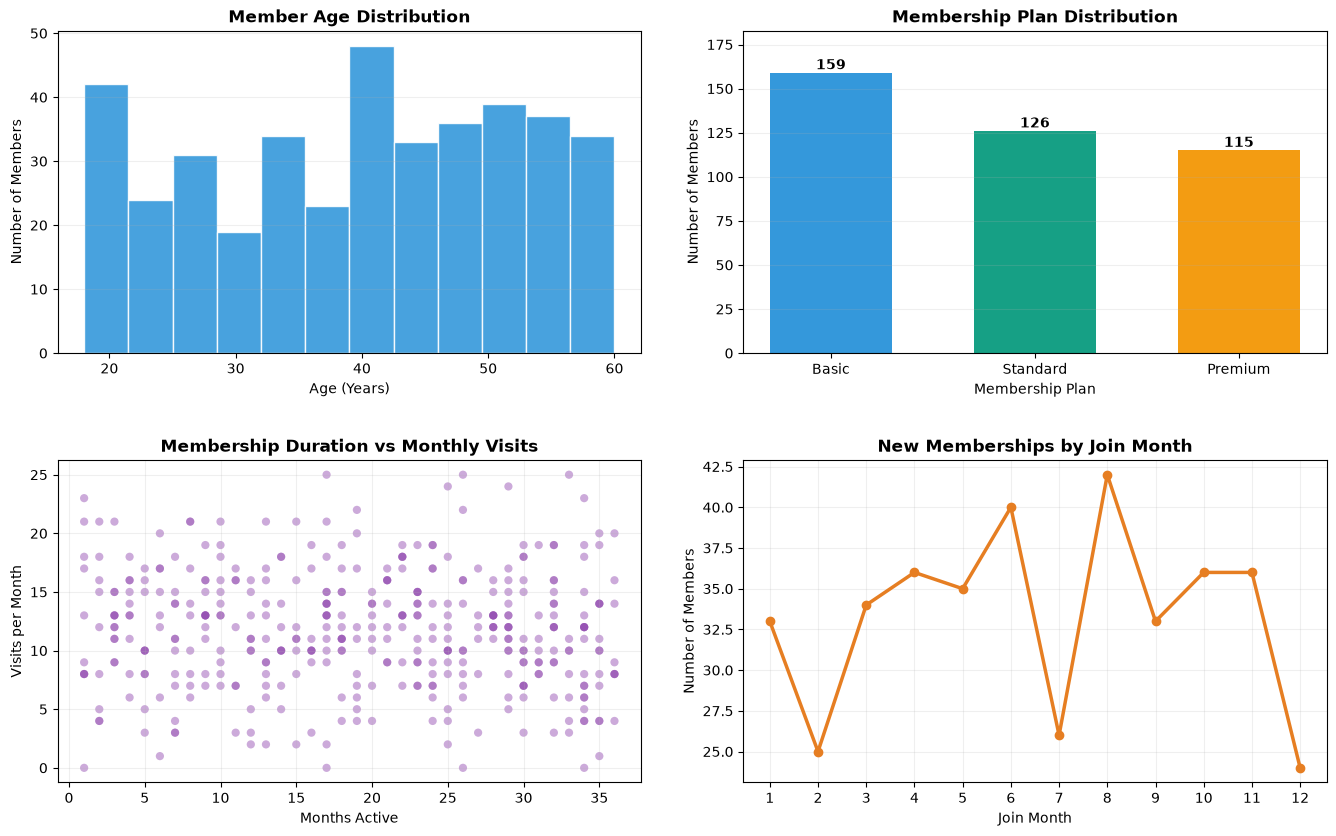

SESSION 7 - TASK 2 COMPLETED
Total Members: 400
Dashboard saved: gym_grid_old_style.png


In [4]:

# MATPLOTLIB SESSION 7 - TASK 2
# Gym Membership Analytics - 2x2 Dashboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("gym_members.csv")

# Validate required columns
required_columns = [
    "age", "plan", "join_month",
    "months_active", "visits_per_month"
]

missing = set(required_columns) - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Prepare summary data
plan_order = ["Basic", "Standard", "Premium"]

plan_counts = (
    df["plan"]
    .value_counts()
    .reindex(plan_order, fill_value=0)
)

monthly_joins = (
    df.groupby("join_month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

# Create dashboard figure
plt.figure(figsize=(14, 9))

# CHART 1 - Age Distribution
plt.subplot(2, 2, 1)

plt.hist(
    df["age"],
    bins=12,
    color="#3498DB",
    edgecolor="white",
    alpha=0.9
)

plt.title("Member Age Distribution", fontweight="bold")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Members")
plt.grid(axis="y", alpha=0.2)

# CHART 2 - Members by Plan
plt.subplot(2, 2, 2)

bars = plt.bar(
    plan_counts.index,
    plan_counts.values,
    color=["#3498DB", "#16A085", "#F39C12"],
    width=0.6
)

plt.title("Membership Plan Distribution", fontweight="bold")
plt.xlabel("Membership Plan")
plt.ylabel("Number of Members")

# Add labels above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{int(height)}",
        ha="center",
        fontweight="bold"
    )

plt.ylim(0, max(plan_counts.values) * 1.15)
plt.grid(axis="y", alpha=0.2)

# CHART 3 - Member Activity
plt.subplot(2, 2, 3)

plt.scatter(
    df["months_active"],
    df["visits_per_month"],
    alpha=0.45,
    s=35,
    color="#8E44AD",
    edgecolors="none"
)

plt.title("Membership Duration vs Monthly Visits", fontweight="bold")
plt.xlabel("Months Active")
plt.ylabel("Visits per Month")
plt.grid(alpha=0.2)

# CHART 4 - Monthly Membership Joins
plt.subplot(2, 2, 4)

months = np.arange(1, 13)

plt.plot(
    months,
    monthly_joins.values,
    marker="o",
    linewidth=2.5,
    color="#E67E22",
    markersize=6
)

plt.title("New Memberships by Join Month", fontweight="bold")
plt.xlabel("Join Month")
plt.ylabel("Number of Members")
plt.xticks(months)
plt.grid(alpha=0.2)

# Professional dashboard layout
plt.tight_layout(pad=3.0)

# Save BEFORE plt.show()
plt.savefig(
    "gym_grid_old_style.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SESSION 7 - TASK 2 COMPLETED")
print("Total Members:", len(df))
print("Dashboard saved: gym_grid_old_style.png")


Task 3: Histograms with Shared Y-Axis

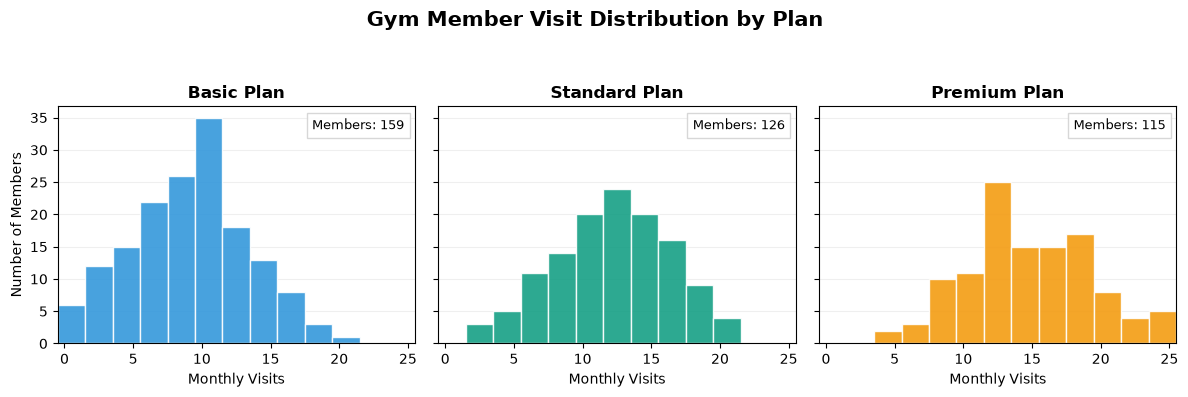

SESSION 7 - TASK 3 COMPLETED

Members by Plan:
plan
Basic       159
Standard    126
Premium     115
Name: count, dtype: int64

Average Monthly Visits by Plan:
plan
Basic        9.13
Standard    12.13
Premium     14.83
Name: visits_per_month, dtype: float64

Saved: gym_visits_by_plan.png


In [6]:

# MATPLOTLIB SESSION 7 - TASK 3
# Monthly Gym Visits by Membership Plan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the gym membership dataset
df = pd.read_csv("gym_members.csv")

# Validate required columns
required_columns = {"plan", "visits_per_month"}

if not required_columns.issubset(df.columns):
    raise ValueError("Required columns are missing.")

# Define membership plans and colors
plans = ["Basic", "Standard", "Premium"]

colors = {
    "Basic": "#3498DB",
    "Standard": "#16A085",
    "Premium": "#F39C12"
}

# Use identical bins for fair comparison
bins = np.arange(-0.5, 26.5, 2)

# Create 1 row and 3 columns with shared Y-axis
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    sharey=True
)

# Draw histogram for each membership plan
for ax, plan in zip(axes, plans):

    plan_data = df.loc[
        df["plan"] == plan,
        "visits_per_month"
    ].dropna()

    ax.hist(
        plan_data,
        bins=bins,
        color=colors[plan],
        edgecolor="white",
        alpha=0.9
    )

    # Individual chart title
    ax.set_title(
        f"{plan} Plan",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Monthly Visits")
    ax.set_xlim(-0.5, 25.5)
    ax.set_xticks([0, 5, 10, 15, 20, 25])
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    # Display membership count
    ax.text(
        0.97, 0.95,
        f"Members: {len(plan_data)}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox=dict(
            facecolor="white",
            edgecolor="lightgray",
            alpha=0.9
        )
    )

# One shared Y-axis label
axes[0].set_ylabel("Number of Members")

# Main title
fig.suptitle(
    "Gym Member Visit Distribution by Plan",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.92])

# Save before showing
fig.savefig(
    "gym_visits_by_plan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print summary
print("SESSION 7 - TASK 3 COMPLETED")
print("\nMembers by Plan:")
print(df["plan"].value_counts().reindex(plans))

print("\nAverage Monthly Visits by Plan:")
print(
    df.groupby("plan")["visits_per_month"]
    .mean()
    .reindex(plans)
    .round(2)
)

print("\nSaved: gym_visits_by_plan.png")


Task 4: Professional Gym Analytics Dashboard

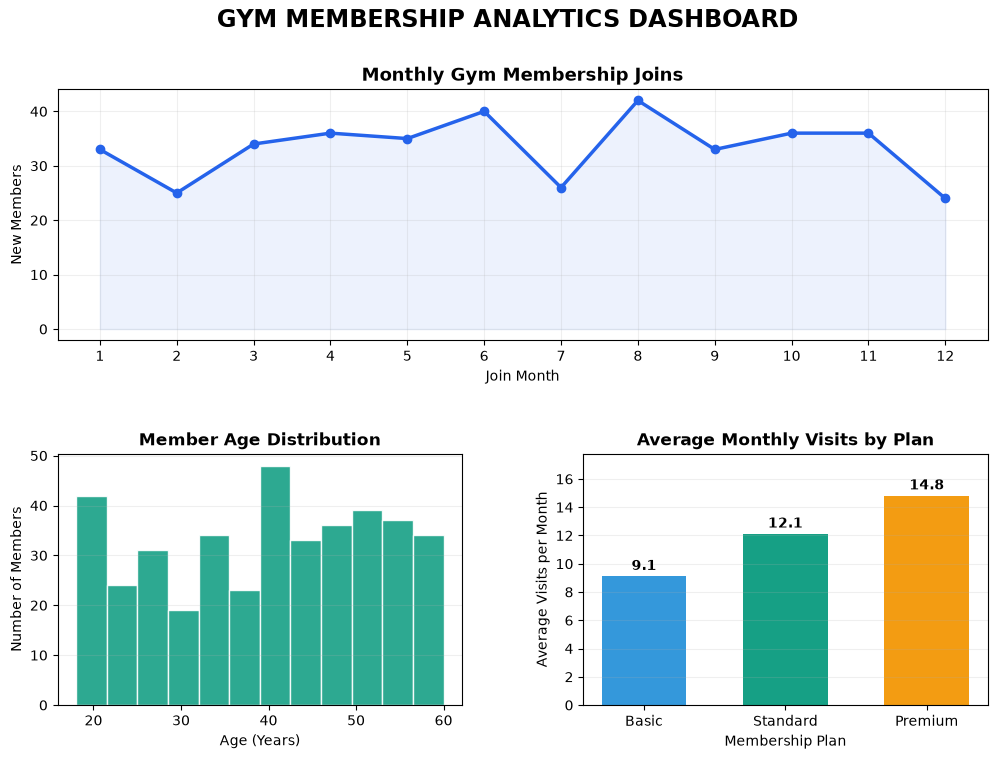

SESSION 7 - TASK 4 COMPLETED
----------------------------------------
Total Members: 400
Average Age: 39.6
Average Monthly Visits: 11.71
Dashboard saved: gym_dashboard.png


In [7]:

# MATPLOTLIB SESSION 7 - TASK 4
# Professional Gym Membership Dashboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load gym membership data
df = pd.read_csv("gym_members.csv")

# Validate dataset
required_columns = [
    "age", "plan", "join_month",
    "months_active", "visits_per_month"
]

if not all(col in df.columns for col in required_columns):
    raise ValueError("Dataset is missing required columns.")

# Prepare monthly membership joins
monthly_joins = (
    df.groupby("join_month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

# Calculate average monthly visits by plan
plan_order = ["Basic", "Standard", "Premium"]

avg_visits = (
    df.groupby("plan")["visits_per_month"]
    .mean()
    .reindex(plan_order)
)

# Create dashboard figure
fig = plt.figure(figsize=(12, 8))

# GridSpec: 2 rows and 2 columns
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1, 1],
    hspace=0.45,
    wspace=0.3
)

# TOP CHART - Monthly Membership Joins
ax1 = fig.add_subplot(gs[0, :])

months = np.arange(1, 13)

ax1.plot(
    months,
    monthly_joins.values,
    marker="o",
    linewidth=2.5,
    color="#2563EB",
    markersize=6
)

ax1.fill_between(
    months,
    monthly_joins.values,
    color="#2563EB",
    alpha=0.08
)

ax1.set_title(
    "Monthly Gym Membership Joins",
    fontsize=13,
    fontweight="bold"
)

ax1.set_xlabel("Join Month")
ax1.set_ylabel("New Members")
ax1.set_xticks(months)
ax1.grid(alpha=0.2)

# BOTTOM LEFT - Member Age Distribution
ax2 = fig.add_subplot(gs[1, 0])

ax2.hist(
    df["age"],
    bins=12,
    color="#16A085",
    edgecolor="white",
    alpha=0.9
)

ax2.set_title(
    "Member Age Distribution",
    fontsize=12,
    fontweight="bold"
)

ax2.set_xlabel("Age (Years)")
ax2.set_ylabel("Number of Members")
ax2.grid(axis="y", alpha=0.2)

# BOTTOM RIGHT - Average Visits by Plan
ax3 = fig.add_subplot(gs[1, 1])

bars = ax3.bar(
    avg_visits.index,
    avg_visits.values,
    color=["#3498DB", "#16A085", "#F39C12"],
    width=0.6
)

ax3.set_title(
    "Average Monthly Visits by Plan",
    fontsize=12,
    fontweight="bold"
)

ax3.set_xlabel("Membership Plan")
ax3.set_ylabel("Average Visits per Month")

# Add labels above bars
for bar in bars:
    height = bar.get_height()

    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.1f}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax3.set_ylim(0, avg_visits.max() * 1.2)
ax3.grid(axis="y", alpha=0.2)

# Overall dashboard title
fig.suptitle(
    "GYM MEMBERSHIP ANALYTICS DASHBOARD",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

# Adjust layout
fig.subplots_adjust(top=0.88)

# Save before displaying
fig.savefig(
    "gym_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display summary
print("SESSION 7 - TASK 4 COMPLETED")
print("-" * 40)
print("Total Members:", len(df))
print("Average Age:", round(df["age"].mean(), 1))
print(
    "Average Monthly Visits:",
    round(df["visits_per_month"].mean(), 2)
)
print("Dashboard saved: gym_dashboard.png")
